# 04. Эффект SMS по сегментам
Сегменты строятся на SQL (`sql/02_client_segments.sql`): частота покупок и средний чек делятся на трети через NTILE, давность, баллы и возраст — через CASE.
В каждой группе считается свой A/B-эффект. Сегменты зафиксированы до просмотра результатов, p-value скорректированы поправкой Холма.

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

con = duckdb.connect()
con.execute("CREATE TABLE features AS SELECT * FROM read_csv_auto('data/features.csv')")
con.execute("CREATE TABLE clients AS SELECT * FROM read_csv_auto('data/data/clients.csv')")

sql = open('sql/02_client_segments.sql').read()
con.execute(f"COPY ({sql}) TO 'data/segments.csv' (HEADER)")

seg = pd.read_csv('data/segments.csv')
print(seg.shape)
seg.head()

Matplotlib is building the font cache; this may take a moment.


(200039, 10)


,client_id,treatment_flg,target,avg_check,freq_group,check_group,recency_group,points_group,age_group,gender
0,c941fda3ac,1,1,1.040000,1. редко,1. низкий,2. 4–9 дней,1. не тратит,3. 46–60,не указан
1,a41eb788d2,0,0,1.290000,1. редко,1. низкий,3. 10–23 дня,1. не тратит,4. 61+,женский
2,5bd2cc6e66,1,0,1.483333,1. редко,1. низкий,2. 4–9 дней,1. не тратит,2. 31–45,не указан
3,62d93734bc,0,0,1.500000,1. редко,1. низкий,2. 4–9 дней,1. не тратит,2. 31–45,не указан
4,f338e4f07e,0,0,1.505000,1. редко,1. низкий,2. 4–9 дней,1. не тратит,2. 31–45,не указан


In [2]:
def effect(d):
    # A/B-тест внутри группы: конверсия с SMS против конверсии без SMS
    sms = d[d['treatment_flg'] == 1]
    no_sms = d[d['treatment_flg'] == 0]
    buy = [sms['target'].sum(), no_sms['target'].sum()]
    n = [len(sms), len(no_sms)]
    z, p = proportions_ztest(buy, n)
    low, high = confint_proportions_2indep(buy[0], n[0], buy[1], n[1])
    return {
        'клиентов': len(d),
        'конв. без SMS, %': no_sms['target'].mean() * 100,
        'конв. с SMS, %': sms['target'].mean() * 100,
        'эффект, п.п.': (sms['target'].mean() - no_sms['target'].mean()) * 100,
        'ДИ от': low * 100,
        'ДИ до': high * 100,
        'p': p,
    }


segments = {
    'freq_group': 'частота покупок',
    'check_group': 'средний чек',
    'recency_group': 'давность покупки',
    'points_group': 'списание баллов',
    'age_group': 'возраст',
    'gender': 'пол',
}

rows = []
for col, name in segments.items():
    for group in sorted(seg[col].unique()):
        if group == 'нет данных':   # 0,4% клиентов с невозможным возрастом
            continue
        row = effect(seg[seg[col] == group])
        row['признак'] = name
        row['группа'] = group
        rows.append(row)

res = pd.DataFrame(rows)
res['p (Холм)'] = multipletests(res['p'], method='holm')[1]
res = res[['признак', 'группа', 'клиентов', 'конв. без SMS, %', 'конв. с SMS, %',
           'эффект, п.п.', 'ДИ от', 'ДИ до', 'p (Холм)']]

overall = effect(seg)['эффект, п.п.']
print(f'Общий эффект: +{overall:.2f} п.п.')
res.round(3)

Общий эффект: +3.32 п.п.


,признак,группа,клиентов,"конв. без SMS, %","конв. с SMS, %","эффект, п.п.",ДИ от,ДИ до,p (Холм)
0,частота покупок,1. редко,66680,35.483,40.028,4.546,3.810,5.280,0.000
1,частота покупок,2. средне,66680,61.446,64.772,3.326,2.594,4.058,0.000
2,частота покупок,3. часто,66679,84.254,85.968,1.714,1.174,2.255,0.000
3,средний чек,1. низкий,66680,65.252,69.733,4.481,3.770,5.191,0.000
4,средний чек,2. средний,66680,61.044,64.153,3.110,2.375,3.843,0.000
5,средний чек,3. высокий,66679,54.673,57.083,2.410,1.656,3.163,0.000
6,давность покупки,1. 1–3 дня,76065,78.208,80.762,2.554,1.981,3.128,0.000
7,давность покупки,2. 4–9 дней,68087,58.034,61.610,3.576,2.840,4.312,0.000
8,давность покупки,3. 10–23 дня,55887,38.827,42.811,3.984,3.170,4.798,0.000
9,списание баллов,1. не тратит,78099,50.221,53.308,3.088,2.387,3.788,0.000


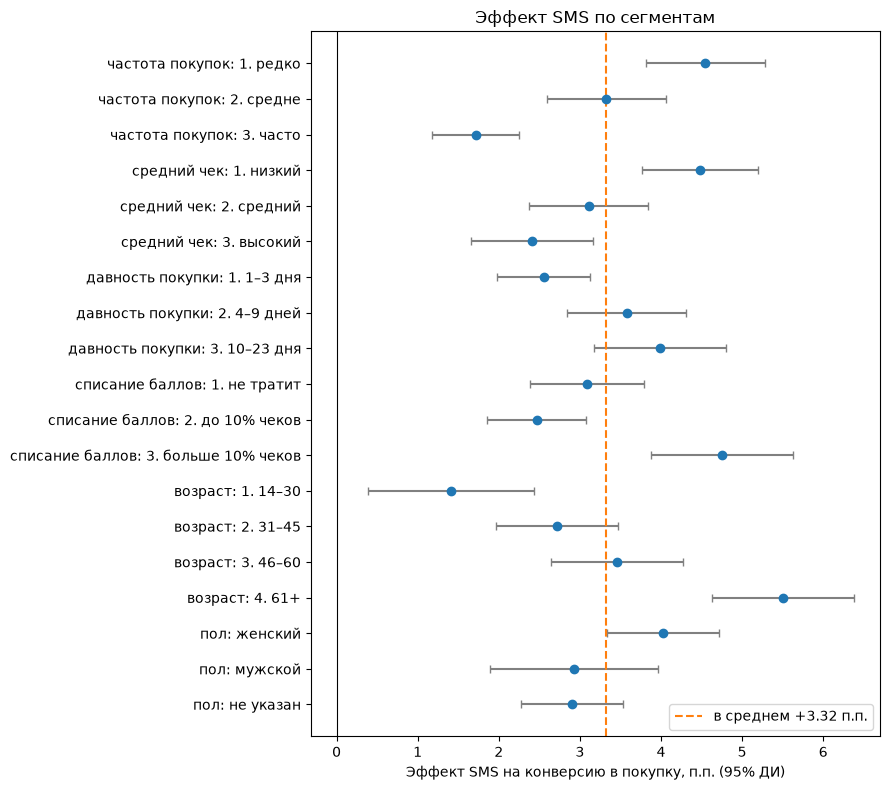

In [3]:
os.makedirs('images', exist_ok=True)

labels = res['признак'] + ': ' + res['группа']
err_low = res['эффект, п.п.'] - res['ДИ от']
err_high = res['ДИ до'] - res['эффект, п.п.']

fig, ax = plt.subplots(figsize=(9, 8))
ax.errorbar(res['эффект, п.п.'], range(len(res)), xerr=[err_low, err_high],
            fmt='o', color='tab:blue', ecolor='gray', capsize=3)
ax.axvline(overall, color='tab:orange', linestyle='--', label=f'в среднем +{overall:.2f} п.п.')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(range(len(res)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel('Эффект SMS на конверсию в покупку, п.п. (95% ДИ)')
ax.set_title('Эффект SMS по сегментам')
ax.legend()
plt.tight_layout()
plt.savefig('images/effect_by_segment.png', dpi=150)
plt.show()

**Итог:**
- SMS повышает конверсию во всех группах (p с поправкой Холма < 0,01), но сила эффекта отличается в 3–4 раза.
- Сильнее всего SMS работает на редких покупателях (+4,5 п.п.), клиентах 61+ (+5,5 п.п.) и тех, кто часто тратит баллы (+4,8 п.п.).
- Слабее всего — на частых покупателях (+1,7 п.п. при конверсии 84% без SMS) и клиентах 14–30 лет (+1,4 п.п.): они покупают и без SMS.